# Import Library and Dataset

Dataset Link : https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv


In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [101]:
df = pd.read_csv('./data/diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# Data Understanding

In [102]:
df.shape

(768, 9)

In [103]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [104]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [105]:
df.isna().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [106]:
df = df.rename(columns={'DiabetesPedigreeFunction':'DPF'})

In [111]:
df.groupby('Outcome')['Outcome'].count()

Outcome
0    500
1    268
Name: Outcome, dtype: int64

<Axes: xlabel='Outcome'>

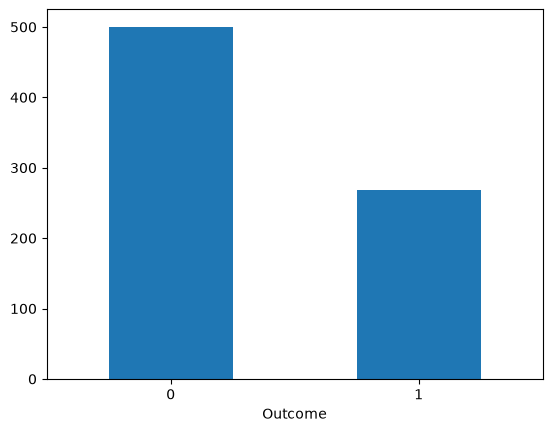

In [112]:
df.groupby('Outcome')['Outcome'].count().plot(kind='bar', rot=0)

array([[<Axes: title={'center': 'Pregnancies'}>,
        <Axes: title={'center': 'Glucose'}>,
        <Axes: title={'center': 'BloodPressure'}>],
       [<Axes: title={'center': 'SkinThickness'}>,
        <Axes: title={'center': 'Insulin'}>,
        <Axes: title={'center': 'BMI'}>],
       [<Axes: title={'center': 'DPF'}>, <Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Outcome'}>]], dtype=object)

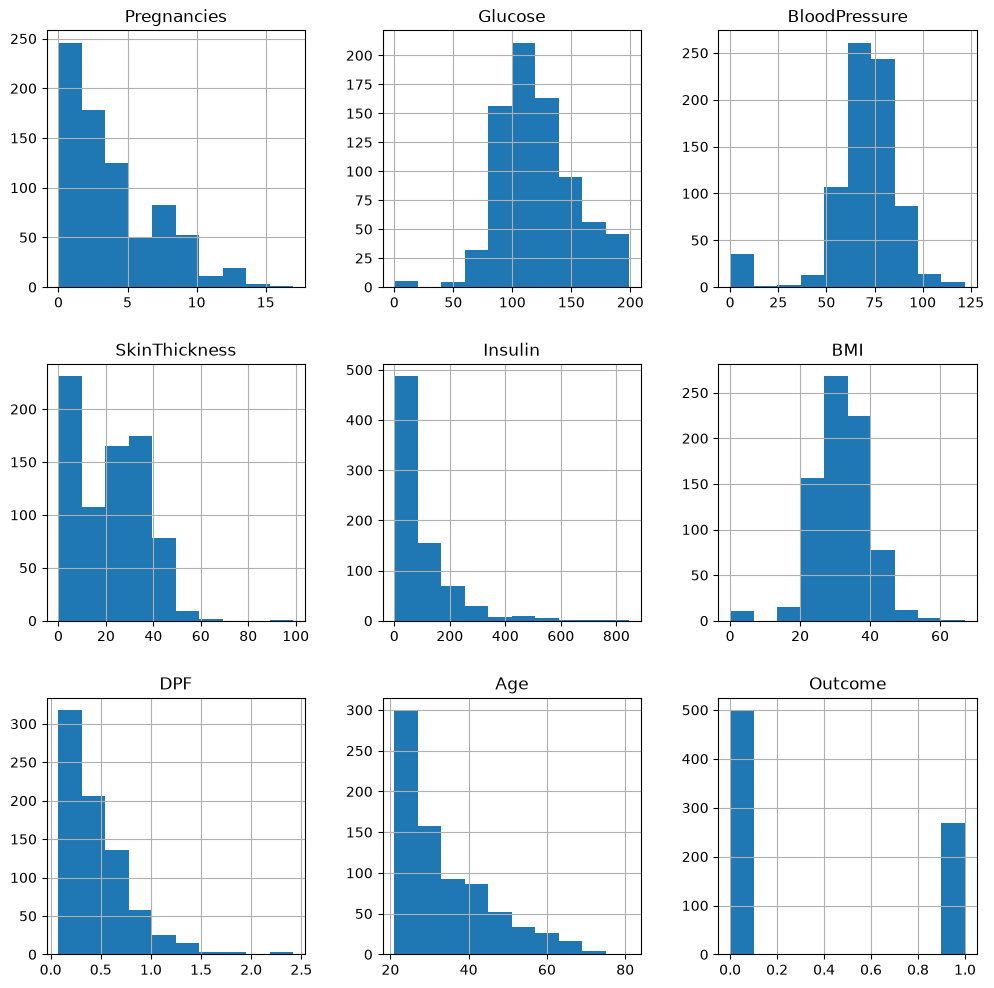

In [113]:
df.hist(figsize=(12, 12))

# Data Cleaning

In [109]:
df_copy = df.copy()
df_copy[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']] = df_copy[['Glucose','BloodPressure','SkinThickness','Insulin','BMI']].replace(0, np.nan)
df_copy.isna().sum()

Pregnancies        0
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
DPF                0
Age                0
Outcome            0
dtype: int64

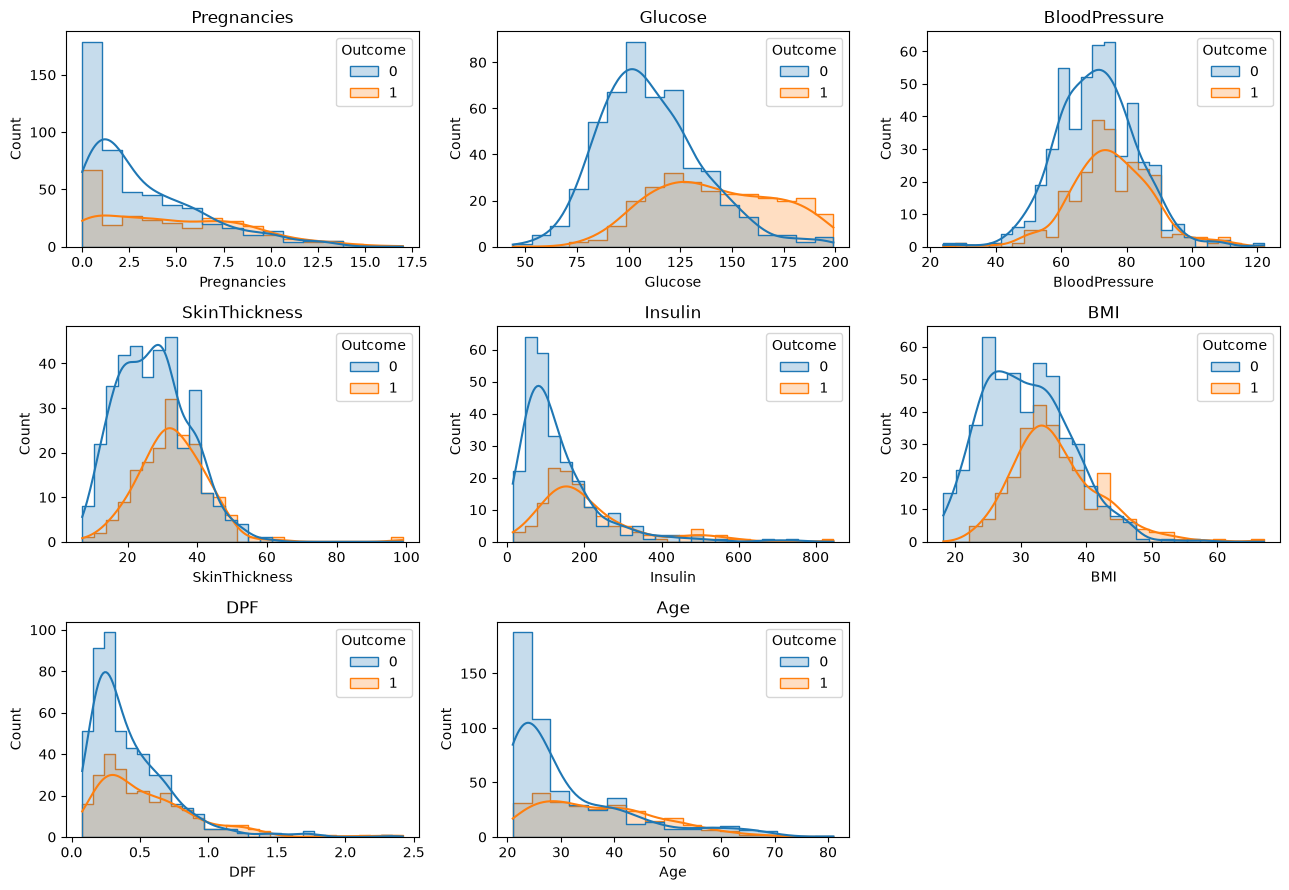

In [115]:
features = [c for c in df.columns if c != "Outcome"]

fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df_copy, x=col, hue="Outcome", kde=True, ax=ax, element="step")
    ax.set_title(col)
for ax in axes.ravel()[len(features):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

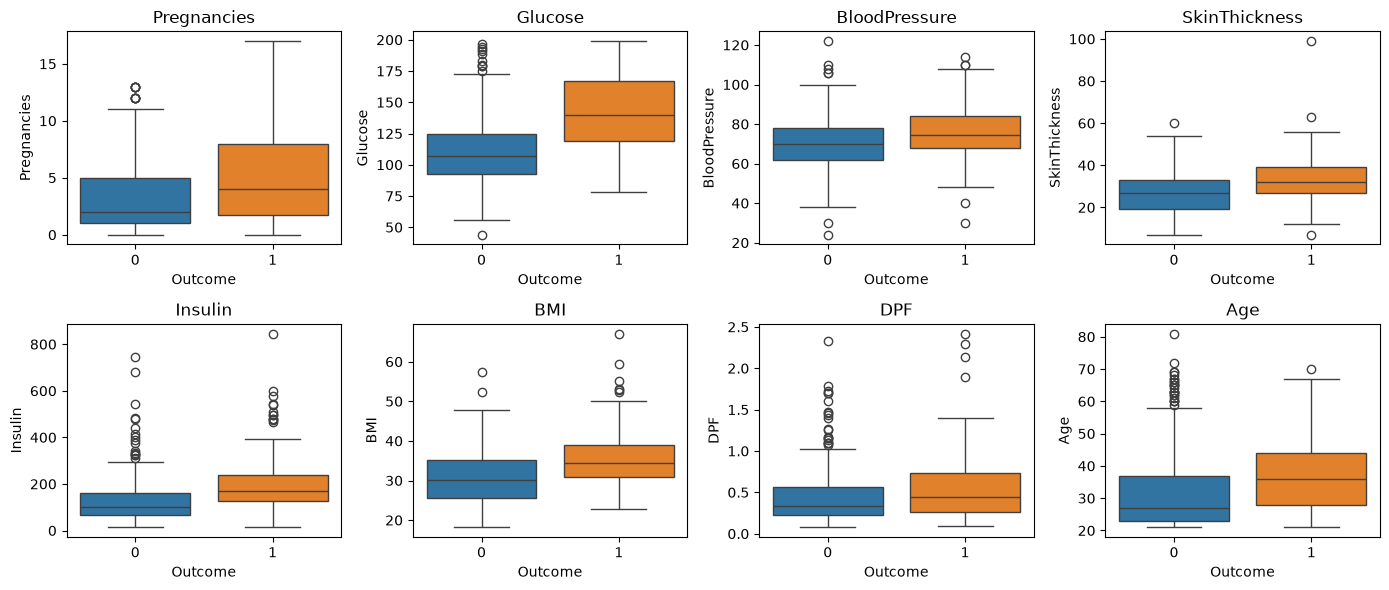

In [117]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df_copy, x="Outcome", y=col, ax=ax, hue="Outcome", legend=False)
    ax.set_title(col)
plt.tight_layout()
plt.show()

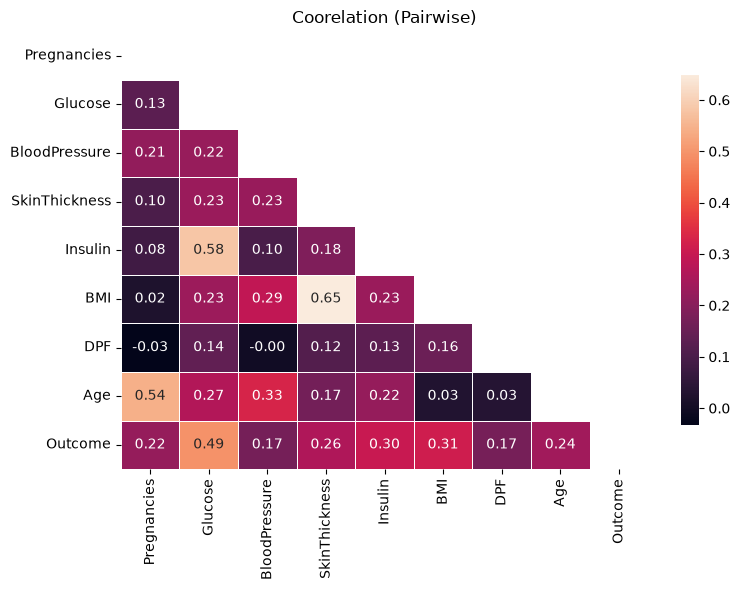

,corr of Outcome
Glucose,0.494650
BMI,0.313680
Insulin,0.303454
SkinThickness,0.259491
Age,0.238356
Pregnancies,0.221898
DPF,0.173844
BloodPressure,0.170589


In [120]:
corr = df_copy.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Coorelation (Pairwise)")
plt.tight_layout()
plt.show()

corr["Outcome"].drop("Outcome").sort_values(ascending=False).to_frame("corr of Outcome")

In [110]:
df_copy.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DPF,Age,Outcome
count,768.000000,763.000000,733.000000,541.000000,394.000000,757.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.535641,12.382158,10.476982,118.775855,6.924988,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,22.000000,76.250000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,141.000000,80.000000,36.000000,190.000000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [121]:
# df_copy['Glucose'] = df_copy['Glucose'].fillna(df_copy['Glucose'].median(), inplace=True)
# df_copy['BloodPressure'] = df_copy['BloodPressure'].fillna(df_copy['BloodPressure'].mean(), inplace=True)
# df_copy['SkinThickness'] = df_copy['SkinThickness'].fillna(df_copy['SkinThickness'].mean(), inplace=True)
# df_copy['Insulin'] = df_copy['Insulin'].fillna(df_copy['Insulin'].median(), inplace=True)
# df_copy['BMI'] = df_copy['BMI'].fillna(df_copy['BMI'].mean(), inplace=True)

In [122]:
# df_copy.hist(figsize=(12, 6))

# Build Model

In [129]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, roc_auc_score, recall_score, f1_score, accuracy_score, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve, precision_score
from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer
from sklearn.inspection import permutation_importance

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import pathlib as pth
import joblib as jlb

random_seed = 42
data_path = pth.Path("./data/diabetes.csv")
model_path = pth.Path("./artifacts")
model_path.mkdir(exist_ok=True)

In [146]:
X = df_copy.drop(columns='Outcome')
y = df_copy['Outcome']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed, stratify=y)
cv_fold = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=random_seed)

def make_pipe(model):
    return Pipeline([
        ('imputer', KNNImputer(n_neighbors=3, add_indicator=True)),
        ('scaler', StandardScaler()),
        ('model', model),
    ])

ratio_boosting = (y_train == 0).sum() / (y_train == 1).sum()

model_pipeline = {
    'logistic_regression': (
        LogisticRegression(max_iter=10000, class_weight='balanced', random_state=random_seed),
        {'model__C' : [0.01, 0.1, 1, 10, 100]},
    ),

    'decison_tree' : (
        DecisionTreeClassifier(class_weight='balanced', random_state=random_seed),
        {
            'model__criterion' : ['gini', 'entropy'],
            'model__max_depth' : [3, 5, 7],
            'model__min_samples_leaf' : [5, 10, 20]
        }
    ),

    'random_forest' : (
        RandomForestClassifier(class_weight='balanced', random_state=random_seed, n_jobs=1),
        {
            'model__n_estimators' : [250, 500],
            'model__max_depth' : [None, 5, 9],
            'model__min_samples_leaf' : [1, 3, 5]
        }
    ),

    'SVM' : (
        SVC(probability=True, class_weight='balanced', random_state=random_seed),
        {
            'model__C' : [0.1, 1, 10],
            'model__kernel' : ['rbf', 'linear'],
            'model__gamma' : ['scale', 'auto']
        }
    ),

    'xgboost' : (
        XGBClassifier(eval_metric='logloss', scale_pos_weight=ratio_boosting, random_state=random_seed, n_jobs=1, verbosity=0),
        {
            'model__learning_rate' : [0.01, 0.1],
            'model__max_depth' : [2, 3, 5],
            'model__n_estimators' : [50, 100, 300],
            'model__subsample' : [0.8, 1]
        }
    ),

    'lightgbm' : (
        LGBMClassifier(class_weight='balanced', random_state=random_seed, n_jobs=1, verbose=-1),
        {
            'model__learning_rate' : [0.01, 0.1],
            'model__num_leaves' : [7, 15],
            'model__n_estimators' : [50, 100, 300],
            'model__min_child_samples' : [10, 20]
        }
    )
}


scores = {"roc_auc": "roc_auc", "recall": "recall", "f1": "f1", "accuracy": "accuracy"}

In [147]:
def test_scores(estimator, X, y, threshold=0.5):
    proba = estimator.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "f1": f1_score(y, pred),
        "roc_auc": roc_auc_score(y, proba),
    }

searches, score = {}, []
for name, (model, grid) in model_pipeline.items():
    print(f"Running {name} ...")
    gs_sv = GridSearchCV(
        make_pipe(model), grid, cv=cv_fold, scoring=scores,
        refit="roc_auc", n_jobs=-1, return_train_score=False,
    )
    gs_sv.fit(X_train, y_train)
    searches[name] = gs_sv

    i = gs_sv.best_index_
    t = test_scores(gs_sv.best_estimator_, X_test, y_test)
    score.append({
        "Model": name,
        "CV ROC-AUC": gs_sv.cv_results_["mean_test_roc_auc"][i],
        "CV ROC-AUC std": gs_sv.cv_results_["std_test_roc_auc"][i],
        "CV Recall": gs_sv.cv_results_["mean_test_recall"][i],
        "CV F1": gs_sv.cv_results_["mean_test_f1"][i],
        "CV Accuracy": gs_sv.cv_results_["mean_test_accuracy"][i],
        "Test ROC-AUC": t["roc_auc"],
        "Test Recall": t["recall"],
        "Test F1": t["f1"],
        "Test Accuracy": t["accuracy"],
        "Best Params": gs_sv.best_params_,
    })

results = (pd.DataFrame(score).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True))
results

Running logistic_regression ...
Running decison_tree ...
Running random_forest ...
Running SVM ...


/opt/miniconda3/envs/ds_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/miniconda3/envs/ds_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/miniconda3/envs/ds_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/opt/miniconda3/envs/ds_env/lib/python3.11/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was dep

Running xgboost ...
Running lightgbm ...


/opt/miniconda3/envs/ds_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/miniconda3/envs/ds_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/miniconda3/envs/ds_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/miniconda3/envs/ds_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/miniconda3/envs/ds_env/lib/python3.11/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted w

,Model,CV ROC-AUC,CV ROC-AUC std,CV Recall,CV F1,CV Accuracy,Test ROC-AUC,Test Recall,Test F1,Test Accuracy,Best Params
0,xgboost,0.841036,0.030066,0.756995,0.685589,0.757350,0.822593,0.685185,0.627119,0.714286,"{'model__learning_rate': 0.01, 'model__max_dep..."
1,random_forest,0.839758,0.034082,0.763307,0.689110,0.759523,0.822593,0.777778,0.672000,0.733766,"{'model__max_depth': 5, 'model__min_samples_le..."
2,logistic_regression,0.836827,0.034649,0.702695,0.661704,0.748669,0.819630,0.703704,0.649573,0.733766,{'model__C': 0.1}
3,SVM,0.834263,0.027941,0.687117,0.659212,0.751904,0.821667,0.537037,0.585859,0.733766,"{'model__C': 0.1, 'model__gamma': 'scale', 'mo..."
4,lightgbm,0.834148,0.027893,0.736840,0.672687,0.749785,0.820556,0.759259,0.672131,0.740260,"{'model__learning_rate': 0.01, 'model__min_chi..."
5,decison_tree,0.800061,0.027786,0.732226,0.651527,0.727522,0.794815,0.814815,0.656716,0.701299,"{'model__criterion': 'gini', 'model__max_depth..."


In [ ]:
best_name = results.loc[0, "Model"]
best_model = searches[best_name].best_estimator_
print("Model terpilih :", best_name)
print("Parameter      :", searches[best_name].best_params_)

proba_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= 0.5).astype(int)

print()
print(classification_report(y_test, pred_test, target_names=["Non-diabetes", "Diabetes"]))

Model terpilih : xgboost
Parameter      : {'model__learning_rate': 0.01, 'model__max_depth': 2, 'model__n_estimators': 300, 'model__subsample': 0.8}

              precision    recall  f1-score   support

Non-diabetes       0.81      0.73      0.77       100
    Diabetes       0.58      0.69      0.63        54

    accuracy                           0.71       154
   macro avg       0.69      0.71      0.70       154
weighted avg       0.73      0.71      0.72       154

